# CAPSTONE PROJECT: UrbanNest Properties House Price Prediction

#### **Goal:** To predict median house value in California districts using Linear Regression, and to replace inconsistent human-judgment pricing.

**Business Problem:** UrbanNest prices homes by human judgment alone, leading to inconsistent estimates, lost revenue, and eroded client trust. This notebook builds, tests, and honestly evaluates a simple Linear Regression model that gives agents a data-backed starting price while being honest about exactly where it can and can't be trusted.

**Dataset:** California Housing Dataset · **Model:** Linear Regression · **Team:** Group 12, Cohort 8 TechCrush Data Science Class.


### 1. DATA LOADING

In [7]:
# Import libraries for data handling
import pandas as pd
import numpy as np

In [8]:
df = pd.read_csv("housing.csv")

In [12]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


### 2. DATA INSPECTION

In [9]:
# How many rows and columns does the dataset have?
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (20640, 10)


In [10]:
df.info()  # Column names, data types and non-null counts (reveals missing values)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [11]:
df.describe()    # Displaying Summary statistics

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [12]:

df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

### 3. DATA CLEANING

In [6]:
import pandas as pd
df = pd.read_csv("housing.csv")
df.isnull().sum()                 ### Checking for missing values

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Only total_bedrooms has missing values (207 rows, about 1% of the data).

Since this is a small percentage and the feature is numeric, we'll fill the missing values with the median of the column. The median is preferred over the mean here because total_bedrooms is right-skewed (a few districts have very large room counts), and the median is less sensitive to those "outliers".

In [14]:
median_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(median_bedrooms)

In [15]:
df.isnull().sum()          ### Confirming no missing values remain.

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [16]:
duplicate_count = df.duplicated().sum()                   ### Checking for duplicates
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Cross-checking obvious Data issues

In [17]:
print("Max house value:", df['median_house_value'].max())
print("Count at max value:", (df['median_house_value'] == df['median_house_value'].max()).sum())

Max house value: 500001.0
Count at max value: 965


**Note:** median_house_value is capped at $500,001 in this dataset. There are several hundred districts sitting exactly at this cap.

We're not removing these rows at the cleaning stage. This is a data characteristic, not an error. We'll keep it in mind since it can affect how well the model predicts high-value homes.

### Saving the cleaned Data Set...

In [18]:
df.to_csv('housing_cleaned.csv', index=False)
print("Cleaned dataset saved. Shape:", df.shape)           ### Cleaned dataset saved

Cleaned dataset saved. Shape: (20640, 10)


### 4. EXPLORATORY DATA ANALYSIS (EDA)

In [62]:
# Import libraries for data handling and plotting
import pandas as pd
df = pd.read_csv('housing_cleaned.csv')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Distributions of Numeric Features

-- Box plot display of all numerical columns alongside their skewness

In [ ]:
import seaborn as sns

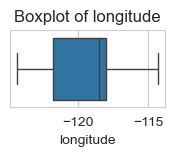

longitude skewness: -0.30


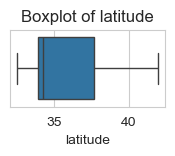

latitude skewness: 0.47


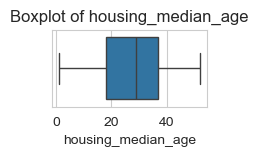

housing_median_age skewness: 0.06


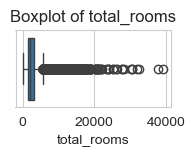

total_rooms skewness: 4.15


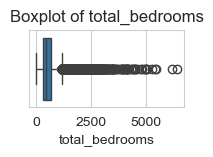

total_bedrooms skewness: 3.48


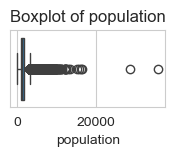

population skewness: 4.94


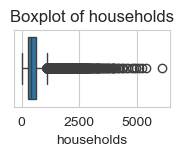

households skewness: 3.41


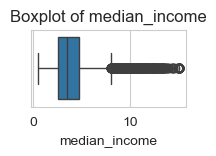

median_income skewness: 1.65


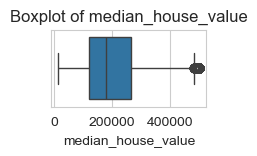

median_house_value skewness: 0.98


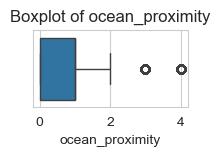

ocean_proximity skewness: 1.02


In [45]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(2,1))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()
    print(f"{col} skewness: {df[col].skew():.2f}")


**Notes:** 
Latitude, longitude and housing age behave normally.
Every heavily-skewed feature (total_rooms, households, population, total_bedrooms) shares the same root cause - block-level aggregation creating a few oversized neighborhoods - except median_house_value, whose skew comes specifically from the price cap, a data limitation rather than a natural outlier pattern.

### Histograms showing the shape and spread of each feature 

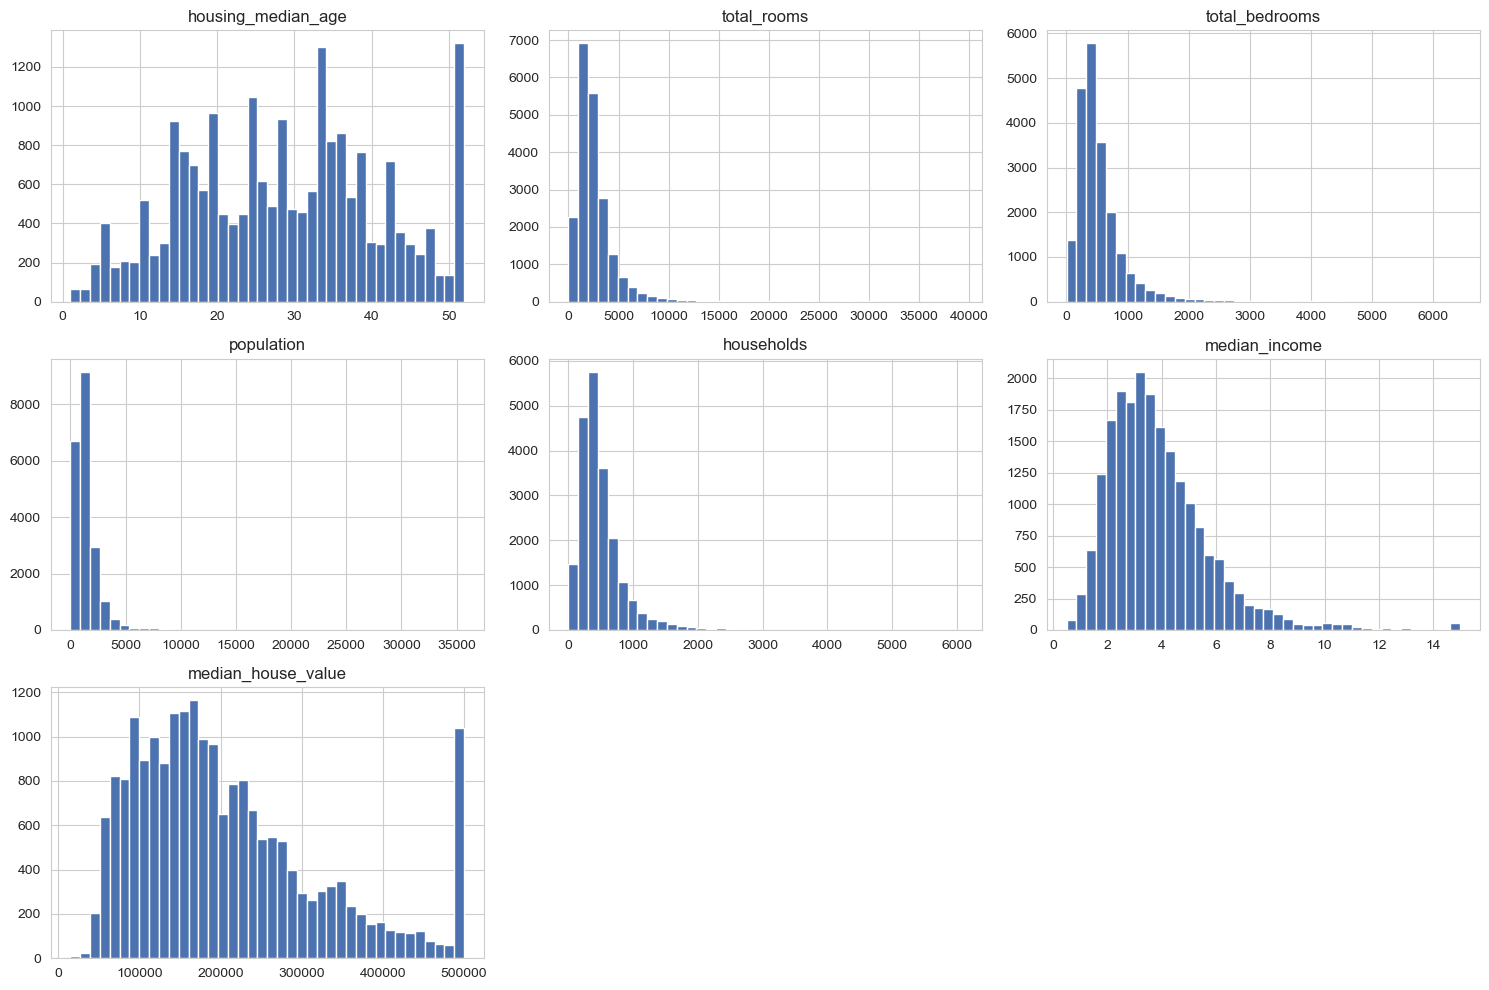

In [12]:
numeric_cols = ['housing_median_age', 'total_rooms', 'total_bedrooms',
                'population', 'households', 'median_income', 'median_house_value']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=40, color='#4C72B0', edgecolor='white')
    axes[i].set_title(col)
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

**Notes:**
Housing_median_age is fairly evenly spread, with a spike at 52 (likely another capped value - districts recorded as "52+ years")

Total_rooms, total_bedrooms, population, and households are all heavily right-skewed too - a small number of districts have very large values, pulling the tail out.
Median_income and median_house_value are right-skewed - most districts are moderate-income/moderate-price, with a long tail of wealthier, higher-priced areas.
median_house_value shows a spike at the far right (~$500,001) - this is the price cap we flagged during data cleaning.


### A correlation heatmap showing which features move together

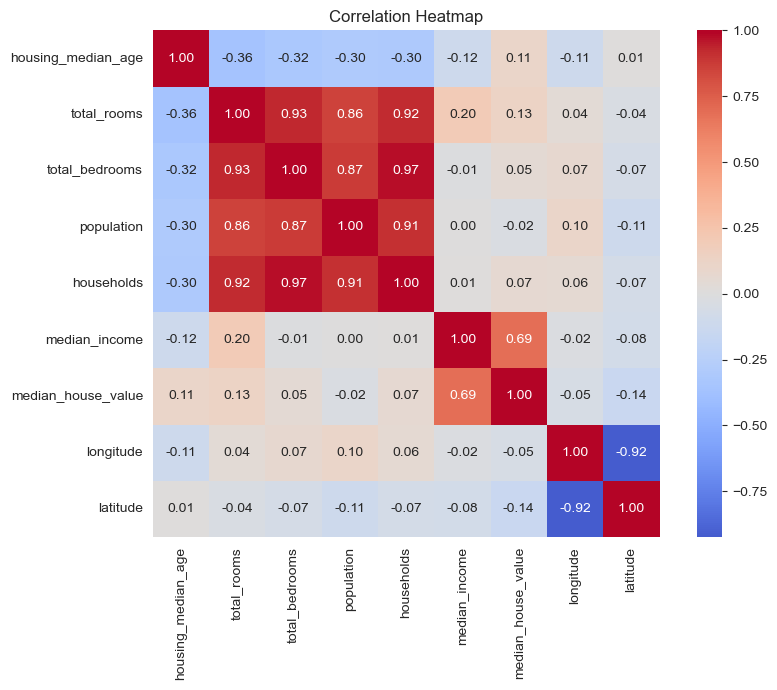

In [4]:
# Correlation between features (near +1 or -1 means a strong link)
corr = df[numeric_cols + ['longitude', 'latitude']].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

**Notes:** 
Median_income has by far the strongest correlation with median_house_value (about 0.69)- wealthier districts have higher-priced homes, as expected
total_rooms, total_bedrooms, population, and households are all highly correlated with each other (all describe the size of a district), but only weakly correlated with house value on their own.
latitude has a moderate negative correlation with house value - this hints at a geographic pricing pattern.

### Income vs. House Value

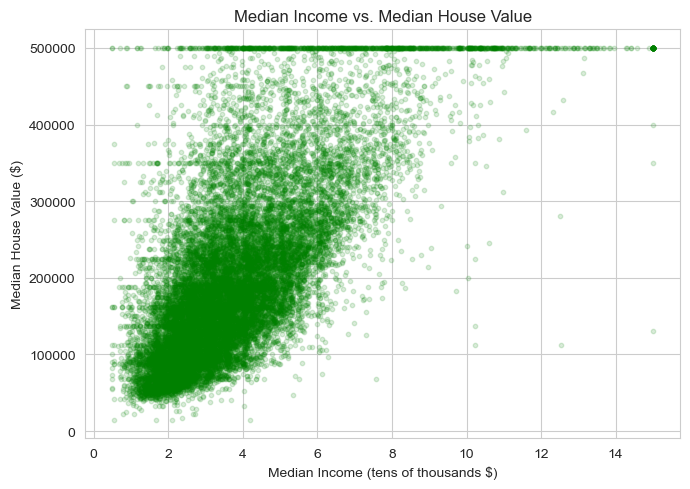

In [49]:
# Scatter plot: each dot is one district (low alpha shows where points pile up)
plt.figure(figsize=(7, 5))
plt.scatter(df['median_income'], df['median_house_value'], alpha=0.15, s=10, color='green')
plt.xlabel('Median Income (tens of thousands $)')
plt.ylabel('Median House Value ($)')
plt.title('Median Income vs. Median House Value')
plt.tight_layout()
plt.show()

**Notes:** 
There's a clear upward trend - higher income areas tend to have higher house values, confirming income as a strong predictor. The flat line of points at the very top ($500,001) is the price cap again - it affects districts across a wide range of income levels, not just the wealthiest, which is a limitation worth remembering when we evaluate the model later.

### Geographic Distribution of House Prices: Latitutde vs. Longitude

-- A scatter plot of latitude/longitude coloured by price reveals where expensive housing is concentrated.

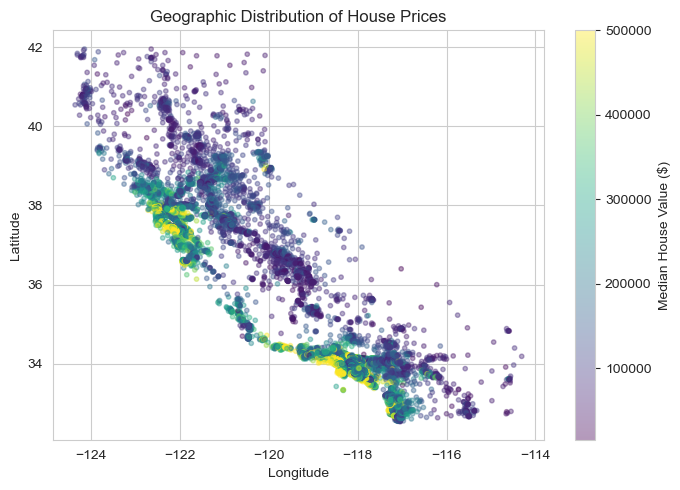

In [22]:
plt.figure(figsize=(7, 5))
sc = plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'],
                  cmap='viridis', alpha=0.4, s=10)
plt.colorbar(sc, label='Median House Value ($)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographic Distribution of House Prices')
plt.tight_layout()
plt.show()

**Notes:**
The most expensive districts cluster along the coast - especially around the Bay Area and Southern California coastline, while inland areas are consistently cheaper. This matches real-world intuition (coastal California real estate is expensive) and confirms location is a meaningful pricing factor, even though ocean_proximity is categorical rather than a single numeric feature.

### House Value by Ocean Proximity

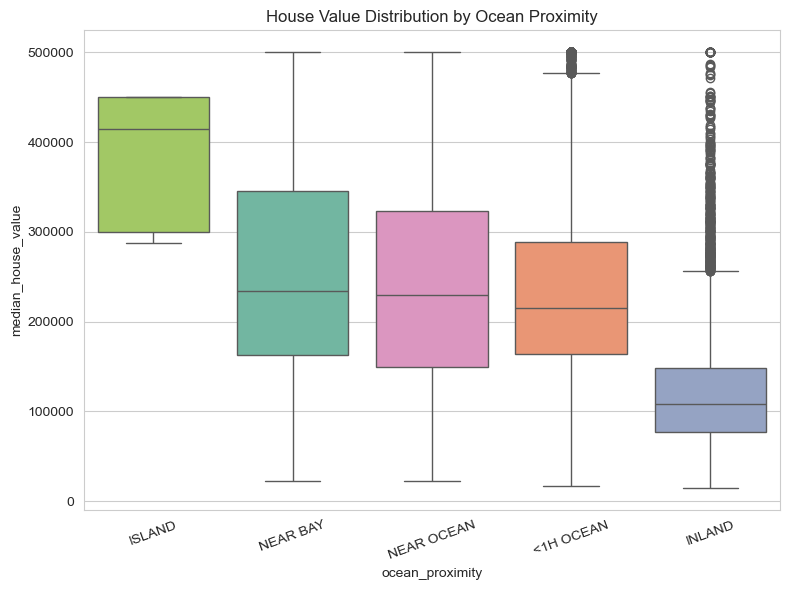

In [14]:
# Order ocean-proximity categories from highest to lowest median price
order = df.groupby('ocean_proximity')['median_house_value'].median().sort_values(ascending=False).index

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='ocean_proximity', y='median_house_value', order=order, hue='ocean_proximity', legend=False, palette='Set2')
plt.xticks(rotation=20)
plt.title('House Value Distribution by Ocean Proximity')
plt.tight_layout()
plt.show()

**Notes:**
ISLAND and NEAR BAY/<1H OCEAN districts have the highest median house values, while INLAND districts are clearly the cheapest. This lines up with the geographic map above and reinforces that proximity to the coast is a strong price driver.

### 5. OUTLIER DETECTION

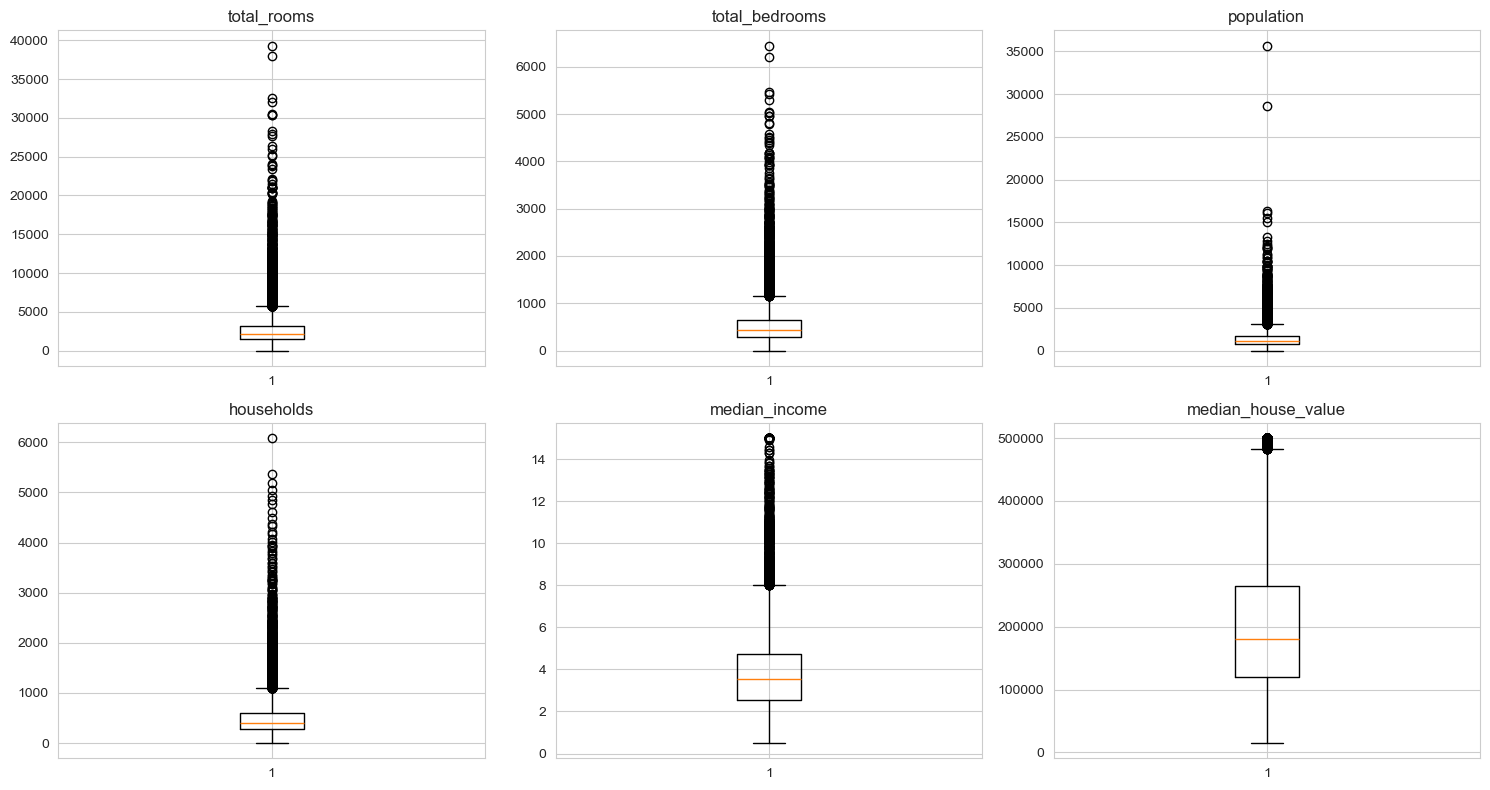

In [57]:
# One boxplot per column; dots beyond the whiskers are supposed outliers
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
box_cols = ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
for i, col in enumerate(box_cols):
    axes[i].boxplot(df[col], vert=True)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

In [11]:
# IQR rule: a value is an outlier if it lies more than 1.5 x IQR beyond Q1 or Q3
def iqr_outlier_count(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outlier_summary = pd.DataFrame({
    'column': box_cols,
    'outlier_count': [iqr_outlier_count(df[c]) for c in box_cols],
})
outlier_summary['pct_of_rows'] = (outlier_summary['outlier_count'] / len(df) * 100).round(2)
outlier_summary

,column,outlier_count,pct_of_rows
0,total_rooms,1287,6.24
1,total_bedrooms,1306,6.33
2,population,1196,5.79
3,households,1220,5.91
4,median_income,681,3.30
5,median_house_value,1071,5.19


**Notes:**
Total_rooms, total_bedrooms, population, and households all show a meaningful share of statistical outliers (districts far larger than typical). These are real extreme values, not data errors as some districts genuinely have far more housing units or population than others. We keep these rows; Linear Regression will be somewhat sensitive to them, which we'll note during model evaluation.
median_income has some high-income outliers- again, real (wealthy districts exist), not errors.
median_house_value outliers are dominated by the capped value at $500,001, which we already flagged in data cleaning.

### 6. PREPROCESSING

Before building the model, we prepare the data:
Separate features (X) from the target (y)
Encode the categorical ocean_proximity column, since Linear Regression needs numeric input
Split into training and testing sets

#### Encode the categorical feature

In [102]:
categories = ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']
dummies.columns = categories
print(dummies)

       <1H OCEAN  INLAND  ISLAND  NEAR BAY  NEAR OCEAN
0              0       0       0         1           0
1              0       0       0         1           0
2              0       0       0         1           0
3              0       0       0         1           0
4              0       0       0         1           0
...          ...     ...     ...       ...         ...
20635          0       1       0         0           0
20636          0       1       0         0           0
20637          0       1       0         0           0
20638          0       1       0         0           0
20639          0       1       0         0           0

[20640 rows x 5 columns]


In [72]:
import pandas as pd
df = pd.read_csv('housing_cleaned.csv')

In [70]:
merged = pd.concat([df, dummies], axis= 'columns')
merged

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,0,1,0,0,0


In [100]:
final_frame = merged.drop(['ocean_proximity'], axis = 'columns')
final_frame

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,0,1,0,0,0


#### Using One-hot encoding 

In [97]:
# One-hot encode ocean_proximity so each category becomes its own 0/1 column
df_encoded = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)
print("Columns after encoding:")
print(df_encoded.columns.tolist())

Columns after encoding:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


#### Separate Features (X) and Target (y)

In [98]:
# Features (X) = every column except the target
X = df_encoded.drop(columns=['median_house_value'])
y = df_encoded['median_house_value']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (20640, 12)
Target (y) shape: (20640,)


#### Train-Test Split

In [104]:
# Tool that randomly splits data into training and test sets
from sklearn.model_selection import train_test_split

# 80% train / 20% test; random_state=42 makes the split repeatable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape[0], "rows")
print("Test set:", X_test.shape[0], "rows")

Training set: 16512 rows
Test set: 4128 rows


**Why Train-Test Split?** Splitting the data lets us train on one portion (80%) and honestly test performance on data the model has never seen (20%), which is a much more realistic estimate of real-world performance.

### 7. BUILDING THE MODEL - LINEAR REGRESSION

#### Train the Model

In [107]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()   # Creates the model
model.fit(X_train, y_train)

print("Model trained successfully.")  # Confirms training worked
print("Number of features used:", X_train.shape[1])

Model trained successfully.
Number of features used: 12


#### Make Predictions on Test Data

In [87]:
y_pred = model.predict(X_test)  # Predict prices for the test set (data the model has never seen)

comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred.round(0)}).head(10)
comparison

,Actual,Predicted
0,47700.0,54055.0
1,45800.0,124225.0
2,500001.0,255489.0
3,218600.0,268002.0
4,278000.0,262769.0
5,158700.0,139606.0
6,198200.0,290665.0
7,157500.0,228265.0
8,340000.0,256507.0
9,446600.0,407924.0


#### What the Model Learned

In [20]:
# One coefficient per feature: the price change for a one-unit increase, other features held constant
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_.round(2)
}).sort_values('Coefficient', ascending=False)
coef_df

,Feature,Coefficient
9,ocean_proximity_ISLAND,136125.07
7,median_income,39473.98
11,ocean_proximity_NEAR OCEAN,3431.14
2,housing_median_age,1102.19
4,total_bedrooms,102.79
6,households,48.25
3,total_rooms,-6.02
5,population,-38.17
10,ocean_proximity_NEAR BAY,-5136.64
1,latitude,-25468.35


**Model Summary Key Takeaways**
Strongest Positive Driver: **Island location** has the largest positive effect on predicted house value, increasing the prediction by approximately \\$136,125.
Major Socioeconomic Driver: **Median income** is a powerful predictor of house prices. A one-unit increase in median_income is associated with an estimated \\$39,474 increase in predicted house value.
Largest Negative Effects: **Inland location** has a substantial negative effect, reducing predicted house value by approximately \\$39,787. 
In addition, increases in latitude and longitude are associated with decreases of roughly \\$25,000 – \\$26,000, reflecting the geographic price patterns captured by the model.
Minimal Direct Contribution: Variables such as total_rooms and population have very small model coefficients \(−$6.02 and −\\$38.17, respectively), suggesting that they contribute little directly to the model's prediction compared with location and income.


### 8. MODEL EVALUATION

In [111]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print(f"R² Score: {r2:.3f}")
print(f"MAE (Mean Absolute Error): ${mae:,.0f}")
print(f"RMSE (Root Mean Squared Error): ${rmse:,.0f}")

R² Score: 0.625
MAE (Mean Absolute Error): $50,671
RMSE (Root Mean Squared Error): $70,061



#### **Interpretation:** 
 **R² = 0.63** - this means the model explains about 63% of the variation in house prices using the features we gave it. The remaining variation comes from factors not in this dataset (property condition, school quality, exact square footage, etc.) and from the price-cap limitation discussed below.
- **MAE = $50,671** - on average, the model's prediction is off by about this amount, in either direction. This gives UrbanNest a realistic sense of the typical margin of error per property.

- **RMSE = $70,061** - similar to MAE but penalizes larger errors more heavily. RMSE being higher than MAE tells us there are some predictions that are quite far off, not just small consistent misses.

**Is this good or bad performance?** For a simple Linear Regression model with no advanced feature engineering, an R² in this range is a reasonable, expected result - it captures the main pricing drivers (income, location) but isn't precise enough to replace human judgment entirely. It's a solid foundational baseline.

#### Predictions vs. Actual Values

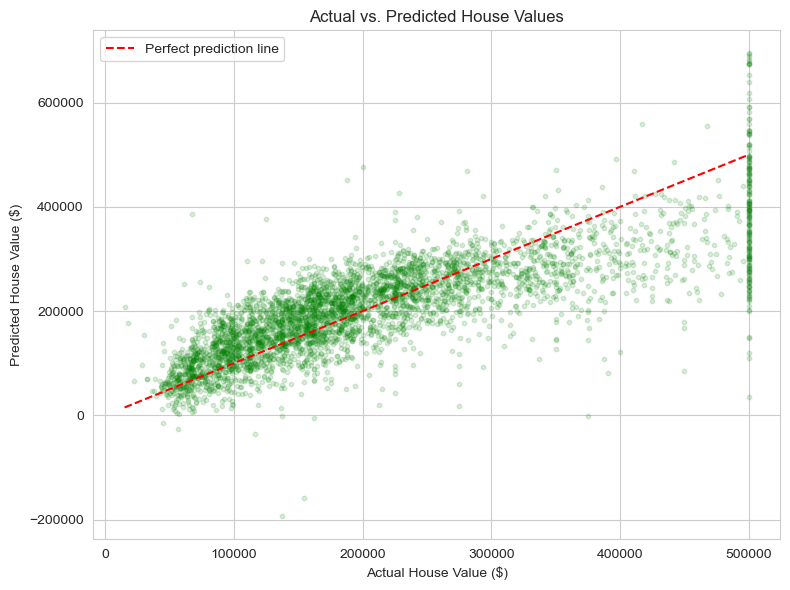

In [89]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.15, s=10, color='green')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Perfect prediction line')
plt.xlabel('Actual House Value ($)')
plt.ylabel('Predicted House Value ($)')
plt.title('Actual vs. Predicted House Values')
plt.legend()
plt.tight_layout()
plt.show()

**What this chart shows:** points close to the red dashed line are accurate predictions. Notice the vertical band of points around $500,001 on the x-axis - these are the capped actual values, where the model predicts a range of values but the true value is artificially fixed. This is the price-cap effect now visible directly in the model's performance.

### WE TRY TO REDUCE OUR FEATURES FOR MODELING

From the correlation heatmap, total_rooms, total_bedrooms, population, and households are all strongly correlated with each other (they all describe the size of a district), but only weakly correlated with median_house_value on their own. This is a sign of multicollinearity - the features carry overlapping information.

We test a reduced model that drops these four size-related columns, keeping only:
longitude, latitude (location)
housing_median_age
median_income (our strongest predictor)
ocean_proximity (encoded)

In [108]:
# Drop the highly-correlated size features
drop_cols = ['total_rooms', 'total_bedrooms', 'population', 'households']
X_reduced = X.drop(columns=drop_cols)

print("Original feature count:", X.shape[1])
print("Reduced feature count:", X_reduced.shape[1])
print("Remaining features:", X_reduced.columns.tolist())

Original feature count: 12
Reduced feature count: 8
Remaining features: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [109]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reduced, y, test_size=0.2, random_state=42)

reduced_model = LinearRegression()
reduced_model.fit(X_train_r, y_train_r)
reduced_pred = reduced_model.predict(X_test_r)

print("Reduced model trained on", X_train_r.shape[1], "features")

Reduced model trained on 8 features


In [112]:
reduced_r2 = r2_score(y_test_r, reduced_pred)
reduced_mae = mean_absolute_error(y_test_r, reduced_pred)
reduced_rmse = mean_squared_error(y_test_r, reduced_pred) ** 0.5

print(f"R² Score: {reduced_r2:.3f}")
print(f"MAE: ${reduced_mae:,.0f}")
print(f"RMSE: ${reduced_rmse:,.0f}")

R² Score: 0.595
MAE: $52,746
RMSE: $72,853


In [120]:
full_r2=r2_score(y_test, y_pred)
full_mae=mean_absolute_error(y_test, y_pred)
full_rmse=mean_squared_error(y_test, y_pred) ** 0.5
                            
comparison = pd.DataFrame({
    'Model': ['Full (12 features)', 'Reduced (8 features)'],
    'R2': [round(full_r2,3), round(reduced_r2,3)],
    'MAE': [round(full_mae,0), round(reduced_mae,0)],
    'RMSE': [round(full_rmse,0), round(reduced_rmse,0)]
})
comparison


,Model,R2,MAE,RMSE
0,Full (12 features),0.625,50671.0,70061.0
1,Reduced (8 features),0.595,52746.0,72853.0


#### **Which Single Feature Predicts Price Best?**
As a simple, visual way to confirm what's really driving this model, we test each feature completely on its own, fitting a tiny one-feature Linear Regression for each column and recording its standalone R² on the test set. This cuts through any interaction effects and shows raw individual predictive power.

In [121]:
single_scores = {}
for col in X.columns:
    m = LinearRegression()
    m.fit(X_train[[col]], y_train)
    single_scores[col] = m.score(X_test[[col]], y_test)

single_scores_series = pd.Series(single_scores).sort_values(ascending=False)
single_scores_series

median_income                 0.458859
ocean_proximity_INLAND        0.242818
ocean_proximity_NEAR OCEAN    0.028240
ocean_proximity_NEAR BAY      0.023053
latitude                      0.021916
total_rooms                   0.017970
housing_median_age            0.012551
households                    0.005228
total_bedrooms                0.002811
longitude                     0.001758
ocean_proximity_ISLAND        0.000741
population                    0.000093
dtype: float64

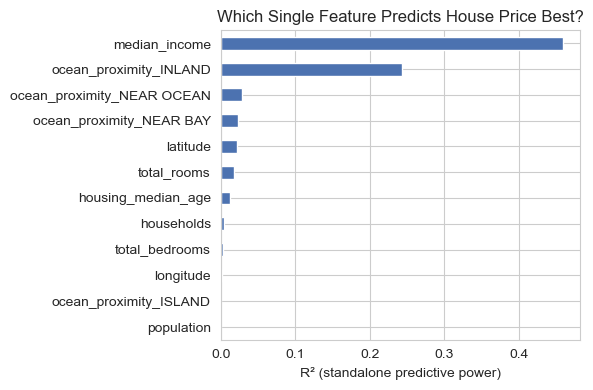

In [122]:
plt.figure(figsize=(6, 4))
single_scores_series.plot(kind='barh', color='#4C72B0')
plt.gca().invert_yaxis()
plt.xlabel('R² (standalone predictive power)')
plt.title('Which Single Feature Predicts House Price Best?')
plt.tight_layout()
plt.show()

#### What this shows: 
median_income alone explains about 46% of the variation in house price - more than any other single feature, and more than most features combined. This is the clearest, simplest confirmation yet of our central finding: income is the dominant signal, with location-related features a distant second. Everything else in the dataset adds refinement, not the core story.

#### **CONCLUSION**

**Recommended model:** the Full Model. It's the strongest simple, interpretable option tested, and the one we recommend UrbanNest deploy as an internal pricing assistant tool.

**Metric	Value	In plain terms**

**R²**	0.625.	Explains ~63% of what drives house prices in this data

**MAE**	$50,671.	Typical prediction is off by about this much

**RMSE**	\\$70,061.	Confirms some predictions (mostly capped-price districts) are further off than average.

**Strongest single predictor**	median_income.	Drives pricing more than any other factor on its own.

**Known limitation**	Price capped at $500,001.	Treat high-end predictions as a lower bound, not a final number.

**Bottom line for UrbanNest:** a simple, honest model that nails the majority of everyday pricing decisions, and is honestly asserts exactly where a human should take over.